## **COMPUTER VISION - Assignment 3 - HELP GUIDE**

In this help guide, you will learn how to design a Convolutional Neural Network (CNN) model to solve a specific task. To this end, the following six points will be covered in this notebook:

1. Access to the image set and labels.
2. Create training, validation, and test subsets, splitting the image set.
3. Model definition: created from scratch or downloaded from a model-zoo.
4. Definition of the optimization algorithm to use (and selection of all the parameters).
5. Definition of the training process: batch policy and loss function.
6. How to do Transfer Learning from a pretrained model.

You must go through the notebook reading the explanations within each cell and trying to understand the code. Different image datasets will be used along the guide.

We will use the **fastai** library (https://docs.fast.ai/). It provides a high-level API that makes the learning process easier and simpler. An electronic book (https://github.com/fastai/fastbook) and a video course (https://www.fast.ai/posts/2022-07-21-dl-coders-22.html) are two additional available external resources.

Remember to use hardware acceleration via GPU (Edit - Notebook Configuration - GPU). Otherwise, many of the computations below will be extremely slow.

In [ ]:
# Install the libraries required by this guide.
!pip install -Uqq fastbook
!pip install -q nbdev

In [ ]:
# Now we SET UP Fastai
import fastbook
fastbook.setup_book()
import fastai
import fastcore
print(f'fastcore version {fastcore.__version__} installed')
print(f'fastai version {fastai.__version__} installed')
from nbdev.showdoc import *
from fastai.vision.all import *

Mounted at /content/gdrive
fastcore version 2.2.35 installed
fastai version 2.8.12 installed


## **Function to display evaluation metrics**

In [ ]:
# Function taken from https://github.com/timeseriesAI/tsai (https://forums.fast.ai/t/plotting-metrics-after-learning/69937)

# Visualizes the evolution of metrics recorded during training.
# Allows comparison of training and validation metrics when both
# are available, grouping them by name.
# Added to the Recorder class using @patch.
# Usage (after training): learn.recorder.plot_metrics()

@patch
@delegates(subplots)
def plot_metrics(self: Recorder, nrows=None, ncols=None, figsize=None, **kwargs):
    metrics = np.asarray(self.values, dtype=float)
    names = [name for name in self.metric_names[1:] if name != 'time']

    if metrics.ndim != 2 or metrics.shape[1] != len(names):
        raise ValueError("Metric names do not match recorded values.")

    # Group training and validation metrics by name
    grouped = {}
    for i, name in enumerate(names):
        if name.startswith('train_'):
            split, base = 'train', name[len('train_'):]
        elif name.startswith('valid_'):
            split, base = 'valid', name[len('valid_'):]
        else:
            split, base = 'valid', name

        grouped.setdefault(base, {})[split] = i

    n = len(grouped)

    if nrows is None and ncols is None:
        nrows = max(1, int(math.sqrt(n)))
        ncols = int(np.ceil(n / nrows))
    elif nrows is None:
        nrows = int(np.ceil(n / ncols))
    elif ncols is None:
        ncols = int(np.ceil(n / nrows))

    figsize = figsize or (ncols * 6, nrows * 4)
    fig, axs = subplots(nrows, ncols, figsize=figsize, **kwargs)
    axs = np.asarray(axs).reshape(-1)

    epochs = np.arange(len(metrics))

    for ax, (name, cols) in zip(axs, grouped.items()):
        for split, color in [('train', '#1f77b4'), ('valid', '#ff7f0e')]:
            if split in cols:
                ax.plot(epochs, metrics[:, cols[split]],
                        color=color, label=split)

        ax.set_title(name)
        ax.set_xlabel('Epoch')
        ax.legend(loc='best')

    for ax in axs[n:]:
        ax.set_axis_off()

    fig.tight_layout()
    plt.show()


## **How to download labeled image datasets from repositories**

Many image datasets are available in `.tar` format from well-known repositories.  That allows us to download and save them to our local drive using a direct call if needed. However, this process **can be pretty slow**. A better alternative is to allow Colab to save them anywhere and return us the access path (see examples below using `untar_data`). A complete list of datasets that are available by default inside the library is included in https://docs.fast.ai/data.external.html

In [ ]:
#!pip install fastdownload # install this package if necessary
# this code save the data in our drive, pretty slow!!!
%cd '/content/gdrive/My Drive'
from fastdownload import FastDownload
base="fastai" # local directory
d = FastDownload(base=base,archive='downloaded', data='extracted')
path=d.get(URLs.MNIST_SAMPLE,force=True)
# check the content in fastai
print(path)

/content/gdrive/My Drive


<div><progress max="3214948" value="3219456"></progress> 100.14% [3219456/3214948 00:00&lt;00:00]</div>

/content/gdrive/My Drive/fastai/extracted/mnist_sample


## **Create training, validation, and test sets by splitting the image dataset**
The code below shows an example of how to create a data loader object (see https://docs.fast.ai/data.load.html) that takes as input a labeled dataset and generates useful batches for the training process. We use `untar_data()` to download the `tar` file. When the dataset is not available as a tarball a different reading process has to be applied. See https://docs.fast.ai/tutorial.datablock.html for many other types of Datablock inputs.  See also https://muttoni.github.io/blog/machine-learning/fastai/2020/12/26/datablocks-vs-dataloaders.html

Each dataset is set-up in a different way. This organization, most of the time, is used to define the item/example/instance label. The code below shows how to create a DataBlock structure from a dataset whose elements are distributed in subdirectories. The item labels are the name of the subdirectory in which they are included.

<div><progress max="3214948" value="3219456"></progress> 100.14% [3219456/3214948 00:00&lt;00:00]</div>

Setting-up type transforms pipelines
Found 14434 items
2 datasets of sizes 12396,2038
Setting up Pipeline: PILBase.create
Setting up Pipeline: parent_label -> Categorize -- {'vocab': ['3', '7'], 'sort': True, 'add_na': False}


Building one sample
  Pipeline: PILBase.create
    starting from
      /root/.fastai/data/mnist_sample/train/7/23607.png
    applying PILBase.create gives
      PILImageBW mode=L size=28x28
  Pipeline: parent_label -> Categorize -- {'vocab': ['3', '7'], 'sort': True, 'add_na': False}

    starting from
      /root/.fastai/data/mnist_sample/train/7/23607.png
    applying parent_label gives
      7
    applying Categorize -- {'vocab': ['3', '7'], 'sort': True, 'add_na': False}
 gives
      TensorCategory(1)

Final sample: (PILImageBW mode=L size=28x28, TensorCategory(1))


Found 14434 items
2 datasets of sizes 12396,2038
Setting up Pipeline: PILBase.create
Setting up Pipeline: parent_label -> Categorize -- {'vocab': ['3', '7'], 'sort': True, 'add_na': False}

Sett

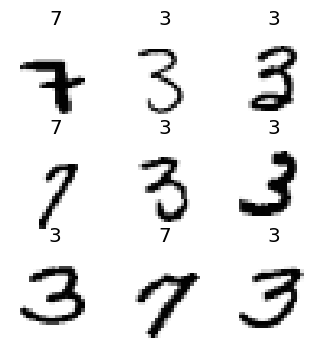

In [ ]:
# Example-1: MNIST
#from fastai.data.external import untar_data, URLs
# Datablock definition from a set of functions
mnistdb = DataBlock(blocks = (ImageBlock(cls=PILImageBW),CategoryBlock), # define the input to the learner
                  get_items = get_image_files, # read all images in subfolders: https://docs.fast.ai/data.transforms.html#get_image_files and https://docs.fast.ai/tutorial.vision.html
                  splitter = GrandparentSplitter(), # generate training and validation sets from the grand parent folder names (https://docs.fast.ai/data.transforms.html#grandparentsplitter)
                  get_y = parent_label)  # define the labels (labels each item with the parent folder name: https://docs.fast.ai/data.transforms.html#parent_label)
# Data load
mnistdl=mnistdb.dataloaders(untar_data(URLs.MNIST_SAMPLE)) # dowload tha dataset and use the DataBlock definition to create the training dataset
#
mnistdl.show_batch(max_n=9, figsize=(4,4)) # shows a batch of images
#
mnistdb.summary(untar_data(URLs.MNIST_SAMPLE))
#


In [ ]:
# Testing the standard transformations already included by default
test_eq(mnistdb.type_tfms[0], [PILImageBW.create]) # To create a PILImageBW
test_eq(mnistdb.type_tfms[1].map(type), [Categorize]) # to create the labels
test_eq(mnistdb.default_item_tfms.map(type), [ToTensor])# to transform in a tensor
test_eq(mnistdb.default_batch_tfms.map(type), [IntToFloatTensor])# to transform in f
doc(DataBlock) # we access to the DataBlock documentation ans source code.


The code below uses a different dataset and a different way to label items. Now, the Datablock structure uses a labeling function defined by us.

<div><progress max="811706944" value="811712512"></progress> 100.00% [811712512/811706944 00:14&lt;00:00]</div>

/root/.fastai/data/oxford-iiit-pet


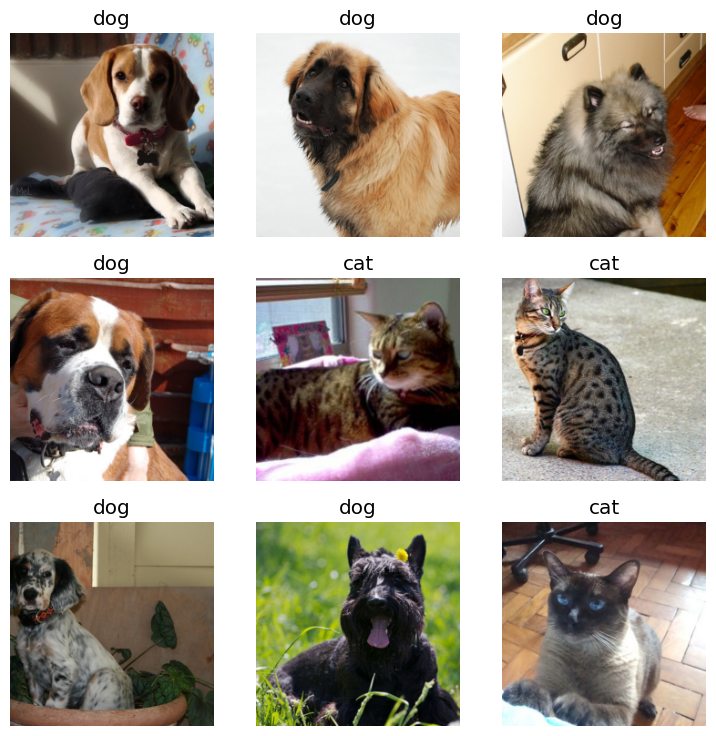

In [ ]:
# Example-2: Dogs and Cats
#
path = untar_data(URLs.PETS)
print(path)  # you realize where the data are saved
def label_func(fname):  # function to create the labels
    return "cat" if fname.name[0].isupper() else "dog"


PETSdb = DataBlock(blocks    = (ImageBlock, CategoryBlock), # define the type of data block
                   get_items = get_image_files, # read all images in subfolders
                   get_y     = label_func, # create the labels
                   splitter  = RandomSplitter(), #split the block for training and test/validation
                   item_tfms = Resize(224)) # resize all images to the same size

PETSdl = PETSdb.dataloaders(path/"images") # create the object to propose batches
PETSdl.show_batch() # shows a batch of images

Fastai provides us with different API levels. The code below shows how to use fastai's Vision API (https://docs.fast.ai/tutorial.vision.html). Now, instead of class DataBlock, we use the class ImageDataLoaders to create the training dataset. Here the splitting in training and validation is already done. In addition, geometrical transformations for items and batches are defined.

<div><progress max="99003388" value="99008512"></progress> 100.01% [99008512/99003388 00:01&lt;00:00]</div>

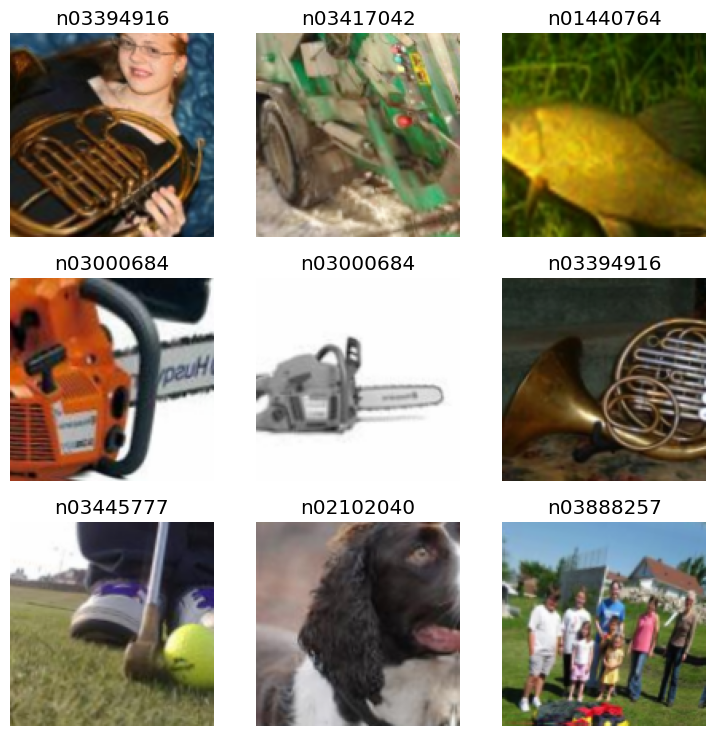

In [ ]:
# Example-3: Imagenette (subset of ImageNet with 10 classes)
# Here we use classes from the VISION API
# IMAGENETTE use the same file configuration as IMAGENET
path = untar_data(URLs.IMAGENETTE_160) # download the data organized in an imageNet-style format
IMAGENETTEdl = ImageDataLoaders.from_folder(path, valid='val',
                                  item_tfms=RandomResizedCrop(128, min_scale=0.35), # Crop image patches
                                  batch_tfms=[Normalize.from_stats(*imagenet_stats),*aug_transforms()])  # normalize with the Imagenet values and apply data augmentation. aug_transforms(...) returns a list, so you need to star it if you put it in another list with additional transforms
IMAGENETTEdl.show_batch() # shows a batch of images
doc(ImageDataLoaders)

## **Understanding the PyTorch training loop**

The following example illustrates a single training iteration in PyTorch, without using FastAI. Our objective is to understand the basic operations that FastAI automates through its `Learner` class.

We define a simple neural network consisting of a `Flatten` operation followed by a fully connected layer. The network receives a minibatch of 8 synthetic grayscale images of size 28 × 28 and produces 10 logits per image, corresponding to 10 possible classes.

The input tensor therefore has shape `(8, 1, 28, 28)`, the ground-truth labels have shape `(8,)`, and the model output has shape `(8, 10)`. All values are randomly generated, so this example is intended to illustrate the training mechanism rather than to obtain meaningful classification results.

In [ ]:
import torch
from torch import nn

# A minimal classification example using synthetic data.
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 10)
)

x = torch.randn(8, 1, 28, 28)
y = torch.randint(0, 10, (8,))

loss_func = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# One training iteration.
model.train()

optimizer.zero_grad()       # Clear gradients from previous steps.
logits = model(x)           # Forward pass.
loss = loss_func(logits, y) # Compute the loss.
loss.backward()             # Compute gradients.
optimizer.step()            # Update model parameters.

print('Training loss:', loss.item())

# Evaluation: no gradient computation or parameter updates.
model.eval()

with torch.no_grad():
    predictions = model(x).argmax(dim=1)

print('Predicted classes:', predictions.tolist())

Training loss: 2.7545509338378906
Predicted classes: [4, 9, 2, 9, 8, 9, 8, 9]


In [ ]:
# Inspect the gradients computed during backpropagation.
for name, parameter in model.named_parameters():
    print(
        name,
        '| shape:', tuple(parameter.shape),
        '| requires_grad:', parameter.requires_grad,
        '| gradient available:', parameter.grad is not None
    )

1.weight | shape: (10, 784) | requires_grad: True | gradient available: True
1.bias | shape: (10,) | requires_grad: True | gradient available: True


**What happens during a training iteration?**

1. `model.train()` switches the network to training mode. This is particularly relevant for layers such as Dropout and Batch Normalization, whose behavior differs between training and evaluation.
2. `optimizer.zero_grad()` clears gradients accumulated from previous iterations. In PyTorch, gradients accumulate by default unless they are explicitly cleared.
3. `logits = model(x)` performs the forward pass, producing 10 logits for each input image.
4. `loss = loss_func(logits, y)` computes the Cross-Entropy Loss between the predictions and the ground-truth labels. PyTorch's `CrossEntropyLoss` accepts logits directly, so applying Softmax explicitly is unnecessary.
5. `loss.backward()` performs backpropagation using automatic differentiation (Autograd). It computes gradients of the loss with respect to the trainable model parameters and stores them in their `.grad` attributes.
6. `optimizer.step()` uses those gradients to update the model parameters according to the selected optimization algorithm, in this case SGD with a learning rate of 0.01.

**What changes during evaluation?**

`model.eval()` switches the network to evaluation mode, while `torch.no_grad()` disables gradient tracking, reducing computational overhead and memory consumption. Unlike training, evaluation does not involve backpropagation or parameter updates.

In this simplified example, predictions are obtained from the same synthetic minibatch used during training. Therefore, they should not be interpreted as a measure of generalization performance.

FastAI's `Learner` automates these operations, including the iteration over minibatches, loss computation, backpropagation, optimizer updates and validation. It also provides additional functionality such as callbacks, learning-rate scheduling and metric tracking.

**Additional reference:** For a more comprehensive introduction to PyTorch, including tensors, automatic differentiation, optimizers, neural network modules, and DataLoaders, see the [MIT 6.7960 Deep Learning — PyTorch Tutorial (Fall 2024)](https://colab.research.google.com/drive/1LwZ2q_4n3JWfBp0nc5S5ImIwtzkO37G0?usp=sharing).

This tutorial is particularly useful for understanding what happens internally when training neural networks with PyTorch, and how these operations relate to the higher-level abstractions provided by FastAI.

## **Choosing the loss function according to the task**

The choice of the loss function depends on the prediction task and on the representation of the ground-truth labels.

| Task | Typical model output | Ground-truth labels | Common loss |
|---|---|---|---|
| Multi-class classification | `(B, C)` logits | `(B,)` integer class indices | Cross-Entropy |
| Regression | `(B,)` or `(B, 1)` continuous predictions | Continuous numerical targets | MSE or MAE |
| Semantic segmentation | `(B, C, H, W)` logits | `(B, H, W)` integer class indices | Pixel-wise Cross-Entropy |

Here, `B` is the batch size, `C` the number of classes, and `H` and `W` the spatial dimensions.

In multi-class classification and segmentation, Cross-Entropy operates on logits and does not require an explicit Softmax layer. For segmentation, the loss is evaluated at the pixel level, and the class dimension is typically `axis=1`.

Some segmentation datasets also include pixels with uncertain or unavailable labels. These pixels can be assigned a special value and explicitly excluded from the loss computation. Importantly, this does not create an additional prediction class.

Always inspect the shapes and values of both model predictions and ground-truth labels before training. A mismatch between the output representation, target encoding, and loss function is a common source of errors.

## **The Learner Object**
The code below shows an example of how to create the object that defines the learning process. It includes relevant pieces of information such as the model, use of pretrained weights, loss function, metrics, learning rate, and number of iterations/epochs. We use the 1cycle learning rate criteria from Leslie Smith to accelerate convergence in optimization. (https://arxiv.org/abs/1803.09820, https://arxiv.org/abs/1708.07120). A range of values for the learning rate is set by fixing a maximum value. This maximum value can be chosen by observing/analyzing the shape of the `lr_find()` output curve. But it is important to notice that this selection process is not trivial, and the shape of the `lr_find()` output curve can serve just as an initial reference. Besides, you will find the calls to show the final results and training curves. If  your model is too big to fit in the GPU memory or too slow, tell the `Learner()` to compute in 16-bit precision, `Learner().to_fp16()`

<div></div>

0.0008317637839354575


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.927096,1.259822,0.478217,0.521783,00:09
1,1.367950,0.929252,0.566624,0.433376,00:09
2,1.104494,0.829562,0.608153,0.391847,00:09


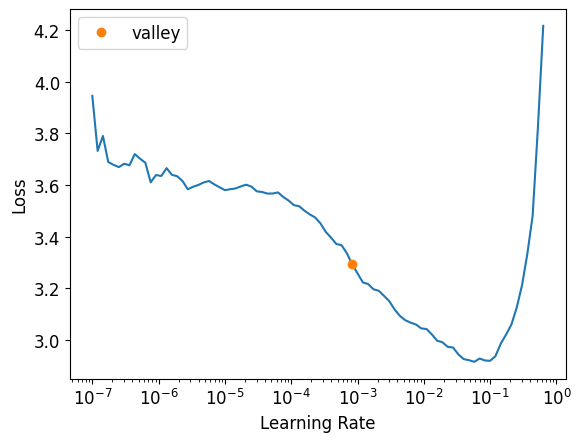

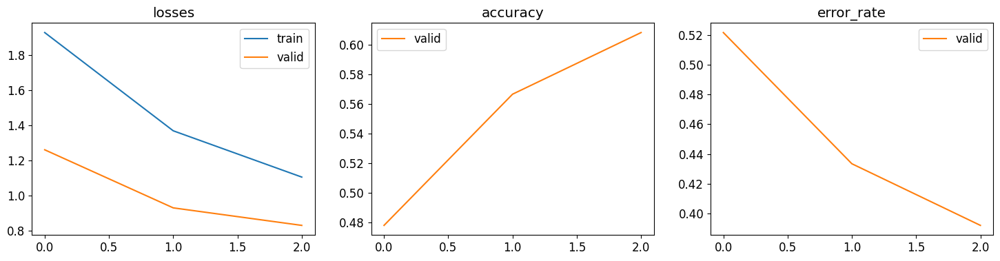

<div></div>

Sequential (Input shape: 64 x 3 x 128 x 128)
Layer (type)         Output Shape         Param #    Trainable 
                     64 x 32 x 64 x 64   
Conv2d                                    864        True      
BatchNorm2d                               64         True      
ReLU                                                           
Conv2d                                    9216       True      
BatchNorm2d                               64         True      
ReLU                                                           
____________________________________________________________________________
                     64 x 64 x 64 x 64   
Conv2d                                    18432      True      
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     64 x 64 x 32 x 32   
MaxPool2d                          

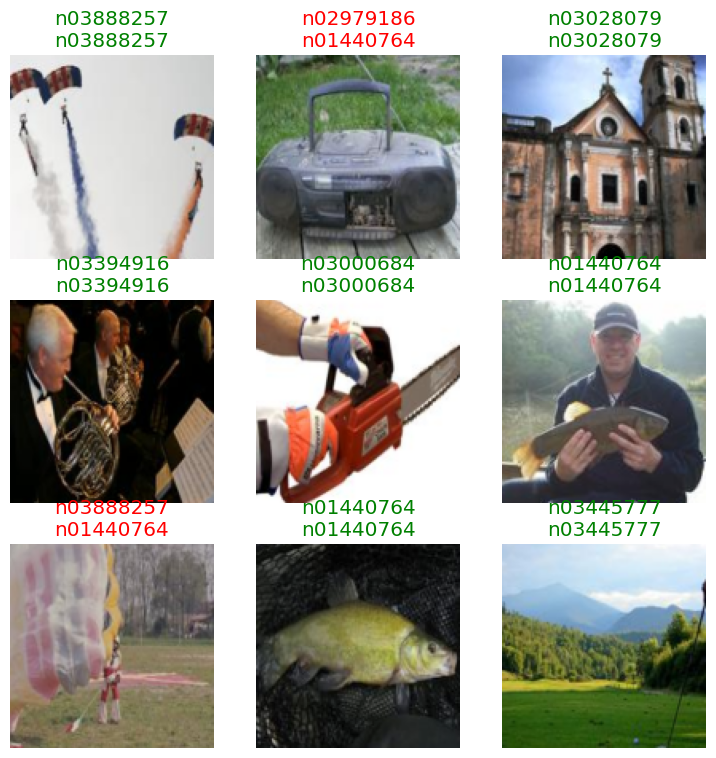

In [ ]:
# Here we use the VISION-API
from fastai.test_utils import *
#
# Example-1: We use "vision_learner" for images
#
dls=IMAGENETTEdl
model=xresnet18
learn = vision_learner(dls, model, metrics=[accuracy,error_rate], loss_func=FocalLossFlat(), pretrained=False) # setting the learning scenario
lr=learn.lr_find() # find the maximum value for lr to use in the next call to the optimizer
print(lr[0])
learn.fit_one_cycle(n_epoch=3, lr_max=lr[0]) # running the optimizer one-cycle
learn.recorder.plot_metrics() # shows accuracy curve along epochs
learn.show_results()
learn.summary() # show all details

We can use the fastai's General API as an alternative to the Vision API. In this case, we instantiate the general Learner class.

<div></div>

epoch,train_loss,valid_loss,accuracy,time
0,1.883313,1.715412,0.423949,00:12
1,1.346951,1.407038,0.544459,00:11
2,1.102072,1.085794,0.651974,00:11
3,0.972344,0.952362,0.699108,00:11
4,0.913613,0.928820,0.701911,00:11


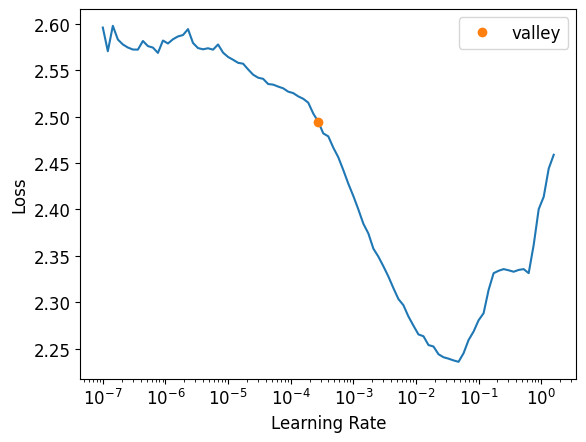

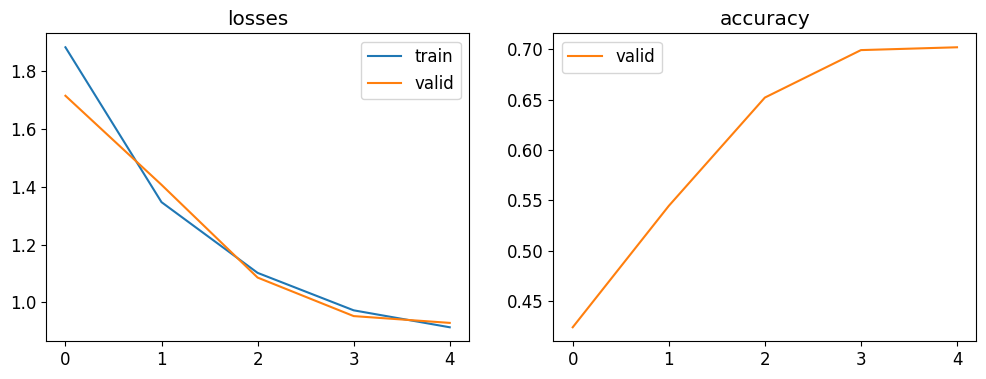

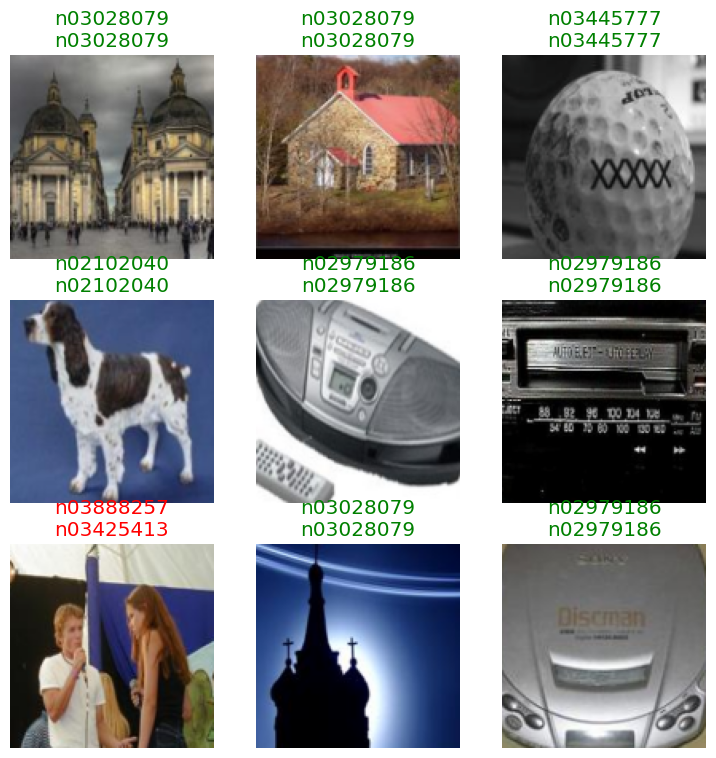

In [ ]:
# Example-2 we use the general Learner class

learn = Learner(IMAGENETTEdl, xresnet34(n_out=10), metrics=accuracy) # no pretrained model
lr=learn.lr_find() # find the maximum value for lr to use in the next call to the optimizer
learn.fit_one_cycle(n_epoch=5, lr_max=lr[0])
learn.recorder.plot_metrics()
learn.show_results()
doc(Learner)

## **How to test a model**

The following reference can be useful for testing in fastai: https://benjaminwarner.dev/2021/10/01/inference-with-fastai

Once we have trained our model we can:
- Perform prediction on a single example:

`learn.predict(example)`

- Perform prediction on a set of examples (test):

`test_dl = learn.dls.test_dl(files_test,with_labels=True)`

`preds, targs = learn.get_preds(dl=test_dl)`

It is key to scale/normalize the test data following exactly the same protocol used in training (using the same mean and std). This is done automatically for you by fastai, using `learn.get_preds` or `learn.dls.test_dl`. See
https://forums.fast.ai/t/do-we-need-to-normalize-single-image-before-running-predict-function-on-it/44301/3 and https://forums.fast.ai/t/99-accuracy-on-valid-data-1-accuracy-on-test-data-what-am-i-missing/80408/2


In [ ]:
# We employ IMAGENETTE_160 for this example
source = untar_data(URLs.IMAGENETTE_160)

dblock = DataBlock(blocks=(ImageBlock, CategoryBlock),
                   splitter=GrandparentSplitter(valid_name='val'),
                   get_items=get_image_files,
                   get_y=parent_label,
                   item_tfms=[RandomResizedCrop(192, min_scale=0.35),
                              FlipItem(0.5)],
                   batch_tfms=Normalize.from_stats(*imagenet_stats))

dls = dblock.dataloaders(source)

learn = Learner(dls, xresnet50(n_out=dls.c), opt_func=ranger,
                loss_func=LabelSmoothingCrossEntropyFlat(),
                metrics=accuracy)

learn.fit_one_cycle(2)

epoch,train_loss,valid_loss,accuracy,time
0,1.738728,1.925273,0.419873,00:15
1,1.417551,1.381018,0.649682,00:15


In [ ]:
source.ls()

[Path('/root/.fastai/data/imagenette2-160/models'), Path('/root/.fastai/data/imagenette2-160/noisy_imagenette.csv'), Path('/root/.fastai/data/imagenette2-160/.DS_Store'), Path('/root/.fastai/data/imagenette2-160/train'), Path('/root/.fastai/data/imagenette2-160/val')]

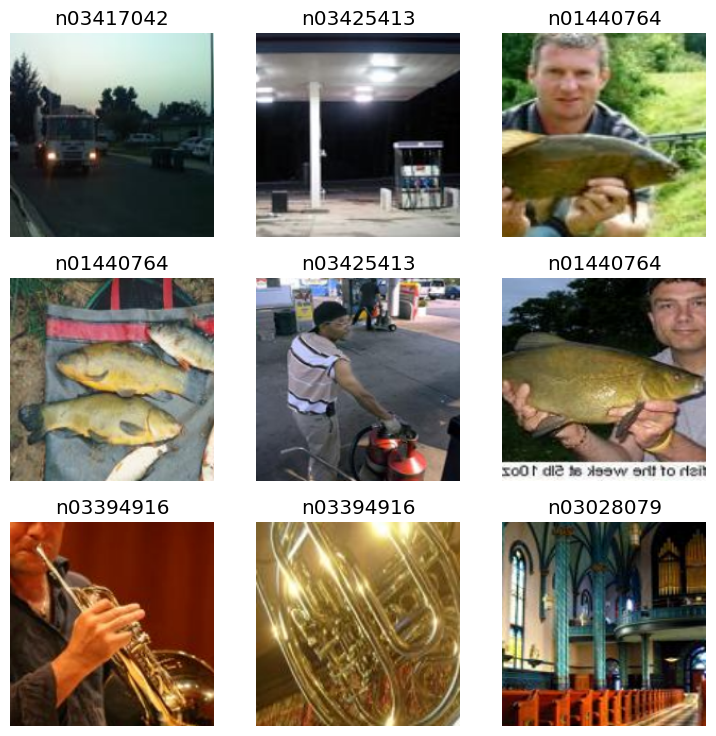

In [ ]:
dls.train.show_batch()

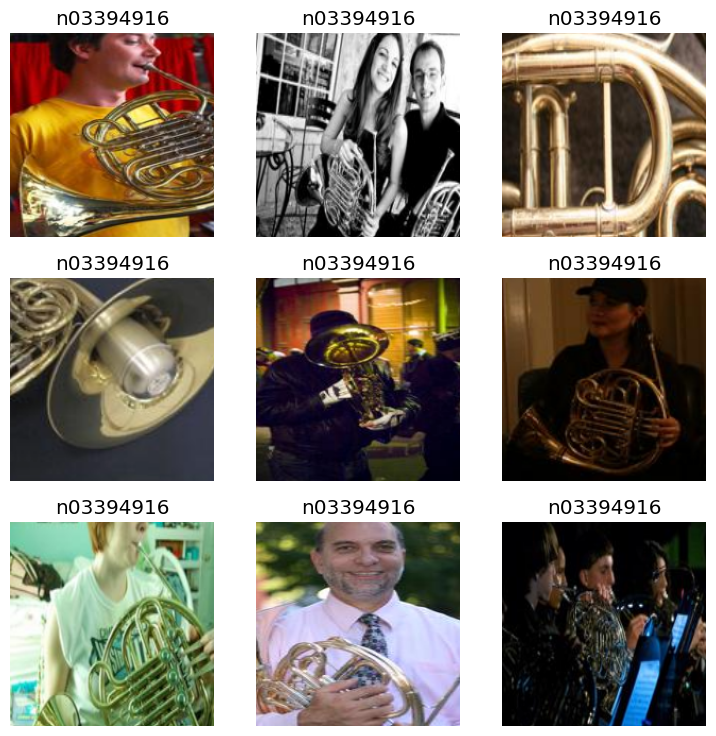

In [ ]:
dls.valid.show_batch()

The validation set is used during model development, for example, to compare architectures or select hyperparameters. An independent test set should be reserved for the final evaluation. In the example below, we use Imagenette, which provides predefined training and validation partitions but no separate official test partition. Therefore, we use the validation images to illustrate how to create a test DataLoader and evaluate a trained model using FastAI. Note that these results should not be interpreted as an independent test evaluation.

In [ ]:
test_files = [fn for fn in sorted((source/'val').glob('**/*')) if fn.is_file()]

test_dl = learn.dls.test_dl(test_files,with_labels=True)



In [ ]:
# We perform prediction on this bunch of data (in this case, the validation set)
preds, targs, _ = learn.get_preds(dl=test_dl, with_decoded=True)

In [ ]:
# We compute accuracy
acc = accuracy(preds, targs)
print('Accuracy on validation images (using test_dl):',
      round(float(acc) * 100, 4), '%')

Accuracy on validation images (using test_dl): 64.9682 %


When dealing with a classification problem, a very valuable tool to analyze the performance is the confusion matrix (https://en.wikipedia.org/wiki/Confusion_matrix). fastai includes classes to build objects to better interpret predictions of a model (https://docs.fast.ai/interpret.html)

Number of test examples: 3925


Test Accuracy
64.96815286624204


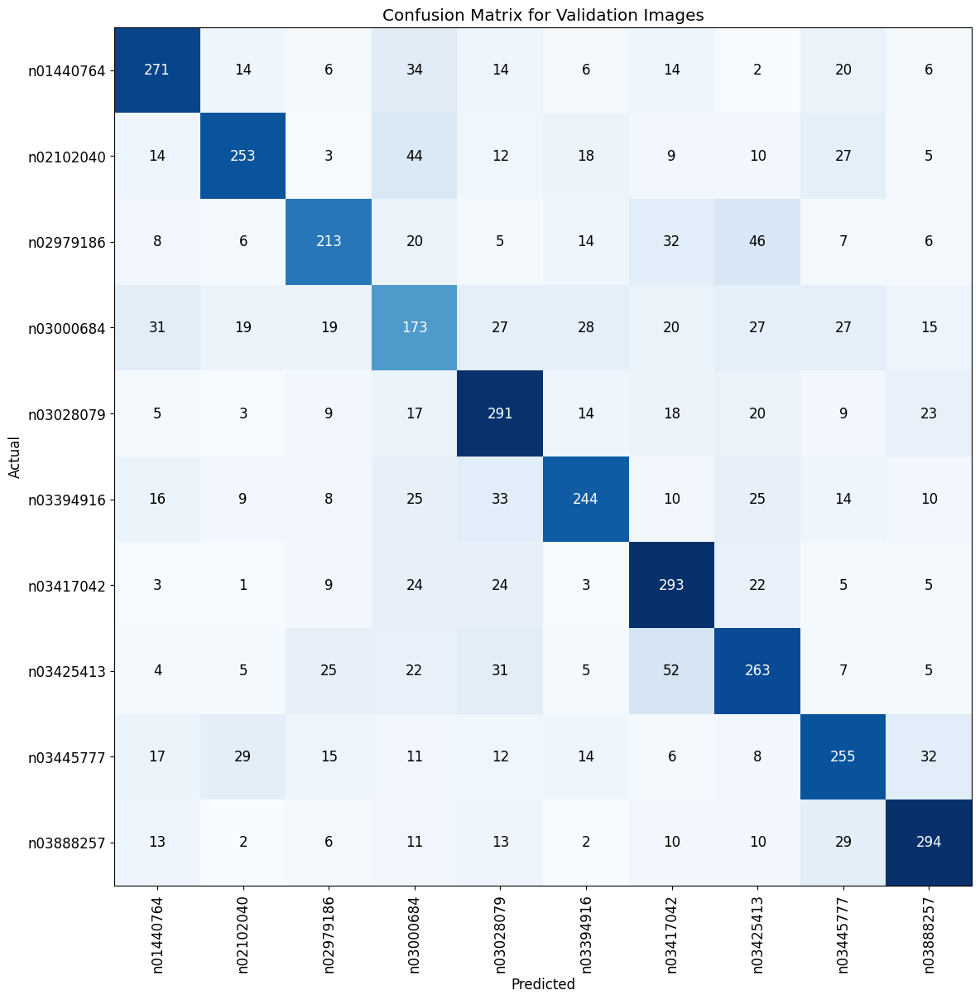

In [ ]:
# We compute the confusion matrix
interp = ClassificationInterpretation.from_learner(learn, 1, test_dl)
cm = interp.confusion_matrix()
print('Number of test examples:', np.sum(cm))
interp.plot_confusion_matrix(figsize=(12, 12),title='Confusion Matrix for Validation Images')
print('Test Accuracy')
print(np.sum(np.diagonal(cm))/np.sum(cm)*100)

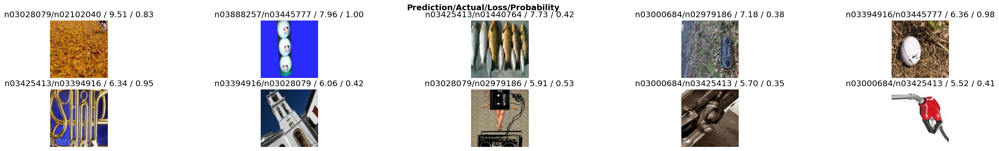

In [ ]:
# we display the n classes with higher confusion level
interp.plot_top_losses(10, nrows=2, figsize=(32,4))

## **The Optimizer Object**

Fastai uses an Optimizer Class that includes most optimizers in PyTorch (see https://docs.fast.ai/examples/migrating_pytorch_verbose.html). The code below shows an example of how to define a fastai optimizer function using a specific optimizer, i.e. Adam. You only have to define a **partial function** with **OptimWrapper** indicating the PyTorch optimizer you want to use.

<div></div>

SuggestedLRs(valley=0.0002754228771664202)

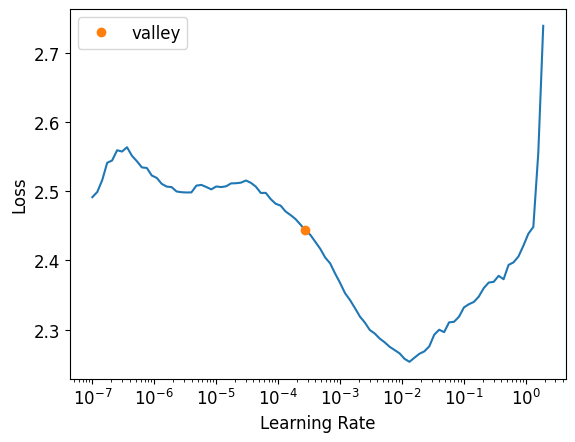

In [ ]:
# See https://docs.fast.ai/losses.html for all loss-function availables
from fastai.optimizer import OptimWrapper

from torch import optim
from functools import partial

Adam = partial(OptimWrapper, opt=optim.Adam) # OptimWrapper class wraps Pytorch optimizer for training
# to use the optimizar from torch use torch.optim.Adam
learn = Learner(
    dls,
    xresnet18(n_out=dls.c),
    metrics=accuracy,
    loss_func=LabelSmoothingCrossEntropy(),
    opt_func=Adam
)

# print(f'Optimizer values:{learn.opt.h[0]}')
learn.lr_find() # Suggest a suitable learning rate for training.

**Fastai's CALLBACKS:** Callback functions are Fastai's design to add any new resource to your code, https://docs.fast.ai/callback.core.html. Here we show an example of use for three different actions: save the best model, show the training curves after each epoch, and EarlyStopping policy.

epoch,train_loss,valid_loss,accuracy,time
0,1.970249,1.858881,0.433376,00:08
1,1.663017,1.565939,0.567389,00:08
2,1.438667,1.426270,0.624968,00:08
3,1.344848,1.401068,0.635669,00:08
4,1.260582,1.378484,0.639236,00:08
5,1.198108,1.203492,0.713885,00:08
6,1.129105,1.290094,0.685350,00:08
7,1.089863,1.187505,0.718471,00:08
8,1.043512,1.191947,0.717452,00:08
9,1.015001,1.125135,0.751338,00:08


Better model found at epoch 0 with valid_loss value: 1.8588807582855225.


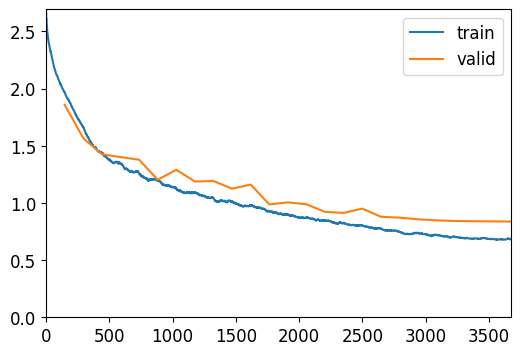

Better model found at epoch 1 with valid_loss value: 1.5659387111663818.
Better model found at epoch 2 with valid_loss value: 1.4262703657150269.
Better model found at epoch 3 with valid_loss value: 1.4010683298110962.
Better model found at epoch 4 with valid_loss value: 1.378483533859253.
Better model found at epoch 5 with valid_loss value: 1.2034915685653687.
Better model found at epoch 7 with valid_loss value: 1.187504529953003.
Better model found at epoch 9 with valid_loss value: 1.125134825706482.
Better model found at epoch 11 with valid_loss value: 0.9869732856750488.
Better model found at epoch 14 with valid_loss value: 0.9217244386672974.
Better model found at epoch 15 with valid_loss value: 0.9132981896400452.
Better model found at epoch 17 with valid_loss value: 0.8793033957481384.
Better model found at epoch 18 with valid_loss value: 0.8714403510093689.
Better model found at epoch 19 with valid_loss value: 0.8569675087928772.
Better model found at epoch 20 with valid_loss v

In [ ]:
# These callback functions are already defined in Fastai
cbs=[SaveModelCallback(), ShowGraphCallback(),EarlyStoppingCallback(min_delta=0.01, patience=5)]
learn.fit_one_cycle(n_epoch=25, lr_max=1.0e-3,cbs=cbs)# One-cycle schedule using the selected Adam optimizer.


## **How to create a CNN model from scratch**

The code below shows how to create an instance of a sequential model and how to visualize a summary of it. In this first example the sizes of the tensors are fixed.

In [ ]:
# LET'S START CHECKING THE SIZE OF A TENSOR
data, label = IMAGENETTEdl.one_batch()
print(f'Data tensor shape: {data.shape}')
print(f'Label tensor shape: {label.shape}')
print(f'This means a tensor of {data.shape[0]} items, where each item has {data.shape[1]} channels of size [{data.shape[2]},{data.shape[3]}]')

Data tensor shape: torch.Size([64, 3, 128, 128])
Label tensor shape: torch.Size([64])
This means a tensor of 64 items, where each item has 3 channels of size [128,128]


Flatten is a class that serves to simplify the coding. In the Net1 class, all the layers parameters are fixed, but that it is not necessary or compulsory. The General Construction shows how to pass parameters to the layers definition.

**Note:** The following CNN is an independent example designed for grayscale images of size 28 × 28 pixels (e.g., MNIST). It is not intended to process the Imagenette images used in the previous example, which have three channels and a resolution of 128 × 128 pixels. The input dimensions determine both the number of channels expected by the first convolutional layer and the number of features entering the first fully connected layer.

In [ ]:
# The simplest way, and the recommended one to perform assignment 3
#
from torch import nn
import torch.nn.functional as F

Net1=nn.Sequential(
    nn.Conv2d(1, 32, 3, 1),
    nn.ReLU(),
    nn.Conv2d(32, 64, 3, 1),
    nn.MaxPool2d(2),
    nn.Dropout2d(0.25),
    nn.Flatten(),
    nn.Linear(9216, 128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 10)
)
total_params(Net1)

(1199882, True)

In [ ]:
# Another approach: in this case, using classes

from torch import nn
import torch.nn.functional as F
from fastai.test_utils import *

# Flatten all dimensions except the batch dimension.
# For example: (B, C, H, W) -> (B, C*H*W).
class Flatten(nn.Module):
    "Flattens an input"
    def forward(self, x): return x.view(x.size(0), -1)
#
# In this example the layers are defined as instances of the Pytorch nn package.
# For this reason are defined inside of the super().__init__ call.
class Net1(nn.Sequential):
  # IT IS KEY HERE TO SET LAYERS SIZES MATCHING THE SPATIAL SIZE OF THE INPUT TENSOR
  # Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0, dilation=1,
  #          groups=1, bias=True, padding_mode='zeros', device=None, dtype=None)
    def __init__(self):
        super().__init__(
            nn.Conv2d(1, 32, 3, 1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, 1),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25),
            Flatten(),
            nn.Linear(9216, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )
model=Net1() # object instantiation
total_params(model) # CHECK the number of parameters and if it’s trainable or not

(1199882, True)

There are more general and modular approaches to define a model. For instance, a model can be considered as a composition of computing blocks, and a class can be defined for each computing block. Each class can be fed with several arguments and is composed of two basic functions: **\__init\__** (definitions) and **forward** (computing). This approach also allows us to implement non-sequential architectures with multiple branches, skip connections, and reusable computational blocks. The forward() method explicitly defines how data flows through these components. An example of how this general strategy to construct a model is carried out can be found here, https://debuggercafe.com/implementing-resnet18-in-pytorch-from-scratch/, which shows how ResNet18 can be implemented from scratch using PyTorch. A basic block can be defined (for instance, computing convolution, ReLU and max pooling) and, later, this can be used several times as part of your neural model.  

The reading of PyTorch documentation regarding the definition and training of neural networks is highly recommended.


Defining a Neural Network in PyTorch:
 *  https://pytorch.org/tutorials/recipes/recipes/defining_a_neural_network.html,
 * https://pytorch.org/tutorials/beginner/introyt/modelsyt_tutorial.html
 * https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html

Training with PyTorch:
  * https://pytorch.org/tutorials/beginner/introyt/trainingyt.html



## **Metrics in multilabel classification**

Below you can find examples of metrics for multi-label classification. In this setting, each image can belong to several classes simultaneously. Predictions are obtained by applying a sigmoid and a threshold independently to each class. We use multi-label accuracy and different aggregations of the F1 score, including macro-F1 and samples-F1.

<div><progress max="1637796771" value="1637801984"></progress> 100.00% [1637801984/1637796771 00:21&lt;00:00]</div>

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 133MB/s]


<div></div>

epoch,train_loss,valid_loss,accuracy_multi,F1(macro),F1(samples),time
0,0.864165,0.575491,0.720199,0.313472,0.345871,00:10


epoch,train_loss,valid_loss,accuracy_multi,F1(macro),F1(samples),time
0,0.618786,0.418917,0.860438,0.456201,0.543449,00:10
1,0.508480,0.336456,0.925319,0.595551,0.696795,00:10


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,target,predicted,probabilities,loss
0,bus;person,aeroplane;bus;car;cow;sheep,"tensor([0.5184, 0.4074, 0.1657, 0.3824, 0.2732, 0.9837, 0.9997, 0.1685, 0.3444, 0.5782, 0.1313, 0.4415, 0.3065, 0.4644, 0.4067, 0.4760, 0.6393, 0.2889, 0.2245, 0.2397])",0.8570837378501892
1,boat;person,boat;car;chair;diningtable;pottedplant,"tensor([0.1139, 0.2712, 0.1219, 0.9682, 0.0767, 0.3375, 0.7266, 0.4115, 0.9705, 0.2922, 0.7379, 0.3085, 0.1329, 0.3308, 0.0740, 0.9763, 0.4560, 0.3148, 0.2435, 0.2649])",0.847904622554779
2,diningtable,chair;diningtable;pottedplant;sofa,"tensor([0.2202, 0.1675, 0.4123, 0.1513, 0.1603, 0.1899, 0.0699, 0.0434, 0.9991, 0.2803, 0.9539, 0.1144, 0.2519, 0.2807, 0.0128, 0.5899, 0.1975, 0.9770, 0.1656, 0.3265])",0.7619807124137878
3,cow,horse;person,"tensor([0.3825, 0.1765, 0.0555, 0.1179, 0.1703, 0.1976, 0.1103, 0.1207, 0.0685, 0.4373, 0.1455, 0.0893, 0.9956, 0.0968, 0.9963, 0.2663, 0.3330, 0.0982, 0.3074, 0.1350])",0.7547814249992371
4,cat;chair;person;pottedplant,bicycle;chair;dog;motorbike;person;pottedplant;sheep;sofa;tvmonitor,"tensor([0.1749, 0.7357, 0.3440, 0.3358, 0.1986, 0.1278, 0.2110, 0.3237, 0.5351, 0.2019, 0.2469, 0.9762, 0.1133, 0.5009, 0.9994, 0.6763, 0.6805, 0.8812, 0.1070, 0.7503])",0.746293842792511
5,person,bird;pottedplant,"tensor([0.1806, 0.3391, 0.9657, 0.4930, 0.2892, 0.1959, 0.1777, 0.1502, 0.3124, 0.3640, 0.1574, 0.1370, 0.2085, 0.4823, 0.0067, 0.5167, 0.2104, 0.2493, 0.2291, 0.4472])",0.736517608165741
6,cat;person;sofa,cat;chair;diningtable;pottedplant;sofa,"tensor([0.3729, 0.4206, 0.2032, 0.3414, 0.3924, 0.4914, 0.1543, 1.0000, 0.5711, 0.1350, 0.5896, 0.2398, 0.2063, 0.2277, 0.0011, 0.5099, 0.2524, 0.7645, 0.1842, 0.4282])",0.7261714935302734
7,person,boat;cow;motorbike;sheep,"tensor([0.4688, 0.3345, 0.3795, 0.7461, 0.4089, 0.4104, 0.0753, 0.4241, 0.1962, 0.6587, 0.2769, 0.3284, 0.1326, 0.5060, 0.0321, 0.4811, 0.6983, 0.4576, 0.3559, 0.4645])",0.7201873660087585
8,person;tvmonitor,chair;diningtable;person;pottedplant;sofa;tvmonitor,"tensor([0.2788, 0.0719, 0.0565, 0.2907, 0.2482, 0.2860, 0.2875, 0.3624, 0.9473, 0.1765, 0.8265, 0.3342, 0.0578, 0.2859, 0.9771, 0.9353, 0.3366, 0.9332, 0.0929, 0.6836])",0.712989330291748


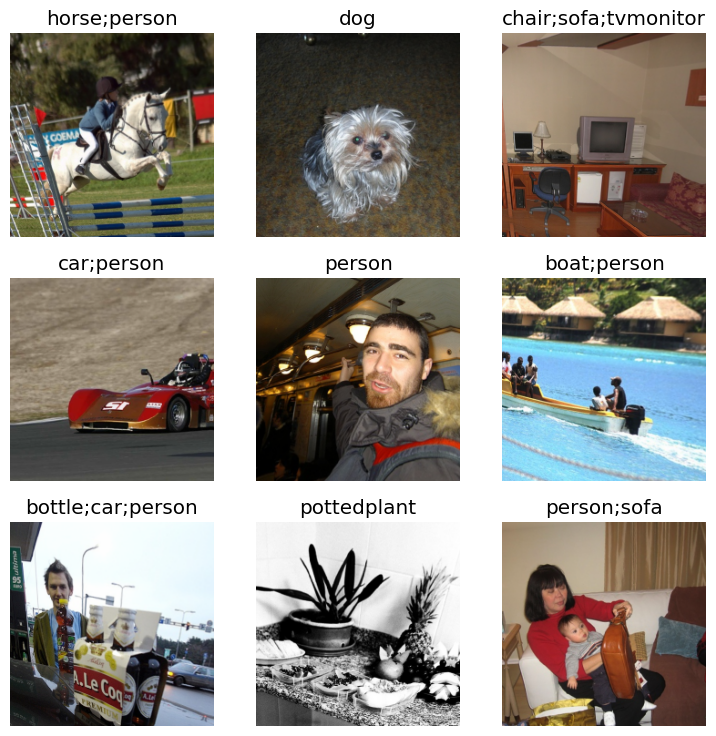

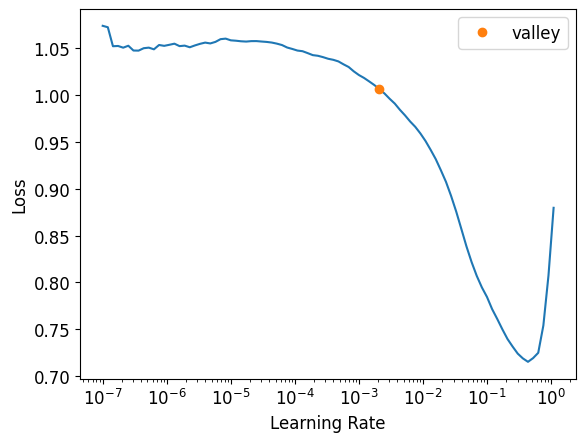

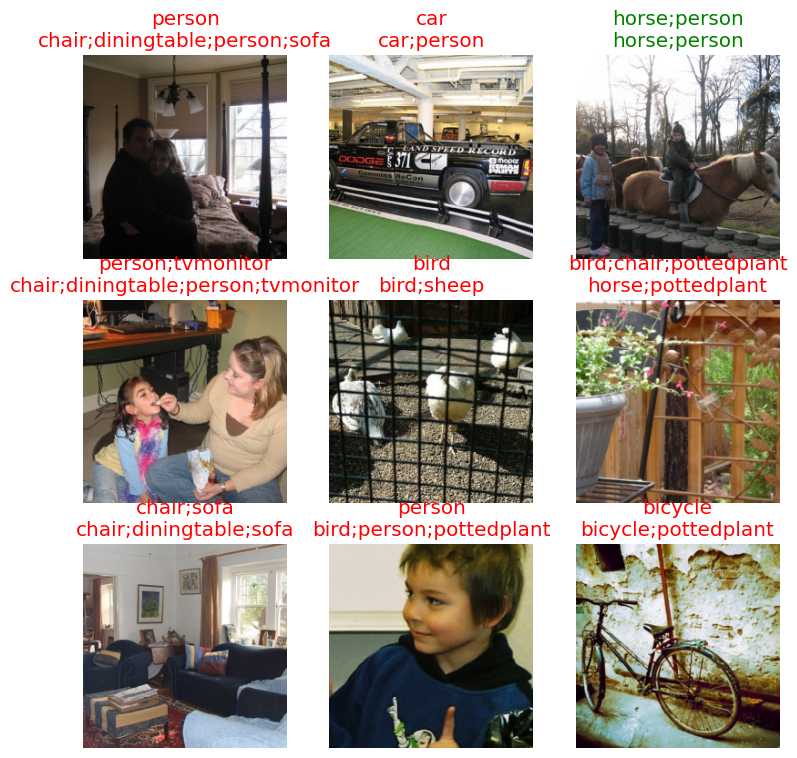

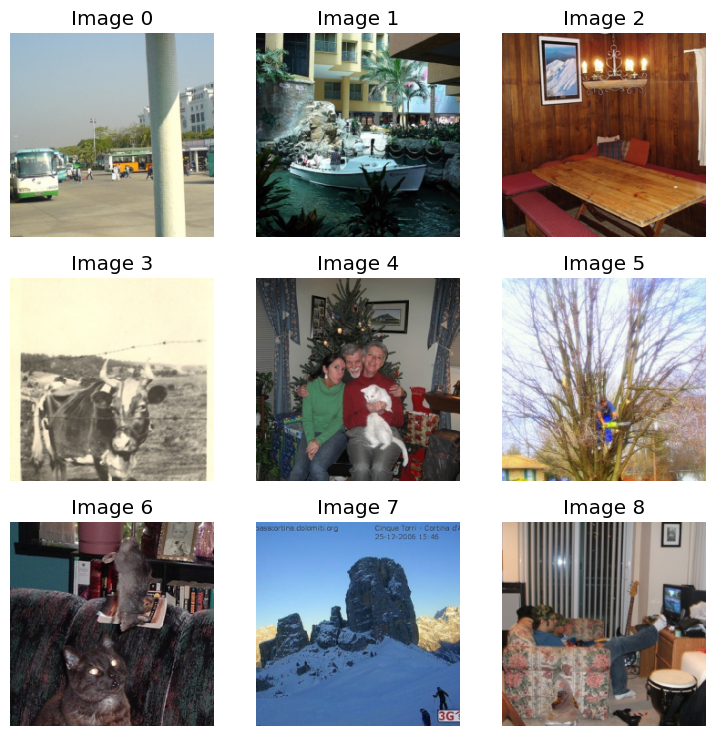

In [ ]:
# Example-1
from fastai.data.external import untar_data, URLs
import pandas as pd
from fastai.vision.all import *

path = untar_data(URLs.PASCAL_2007)
path.ls()
df = pd.read_csv(path/'train.csv')
df.head()
dls = ImageDataLoaders.from_df(df, path, folder='train', valid_col='is_valid', label_delim=' ',
                               item_tfms=Resize(460), batch_tfms=aug_transforms(size=224))
dls.show_batch()
#
f1_macro = F1ScoreMulti(thresh=0.5, average='macro')
f1_macro.name = 'F1(macro)'
f1_samples = F1ScoreMulti(thresh=0.5, average='samples')
f1_samples.name = 'F1(samples)'
learn = vision_learner(dls, resnet50, metrics=[partial(accuracy_multi, thresh=0.5),f1_macro,f1_samples])
lr=learn.lr_find()
learn.fine_tune(2, lr[0])
learn.show_results()
# Showing the training improvement
#
learn.predict(path/'train/000005.jpg') # sample prediction
#
# Now we  check where the model did its worse
interp = Interpretation.from_learner(learn)
interp.plot_top_losses(9)

<div></div>

epoch,train_loss,valid_loss,accuracy_multi,F1(macro),F1(samples),time
0,0.874658,0.582298,0.709821,0.306438,0.334679,00:09


epoch,train_loss,valid_loss,accuracy_multi,F1(macro),F1(samples),time
0,0.652343,0.461615,0.824203,0.407896,0.484281,00:10
1,0.559959,0.401844,0.878187,0.486383,0.589397,00:10


(['chair', 'cow', 'diningtable', 'sofa', 'tvmonitor'],
 tensor([False, False, False, False, False, False, False, False,  True,  True,  True, False, False, False, False, False, False,  True, False,  True]),
 tensor([0.2405, 0.1708, 0.4163, 0.3242, 0.1639, 0.1445, 0.0314, 0.0877, 0.9972, 0.5164, 0.9269, 0.2255, 0.2018, 0.2125, 0.2130, 0.3677, 0.3224, 0.8956, 0.1219, 0.5888]))

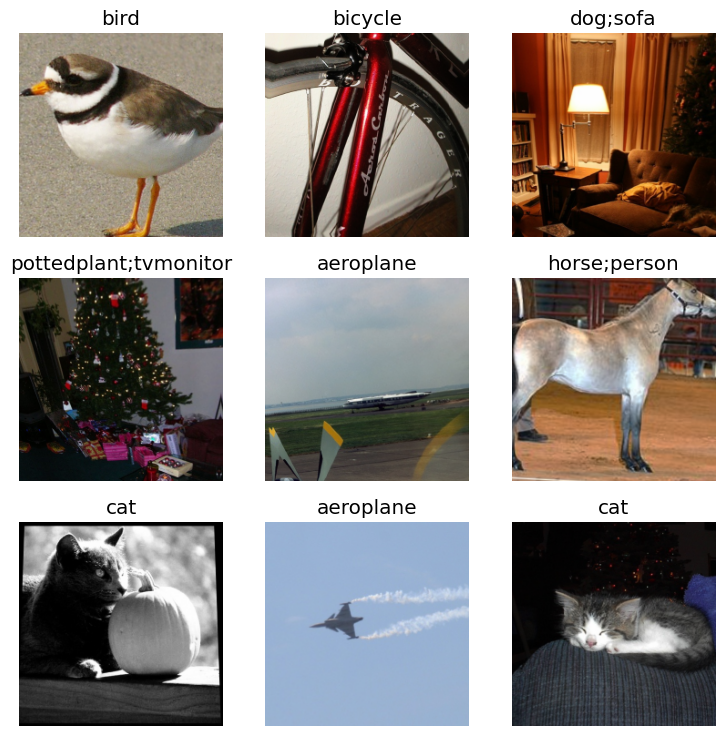

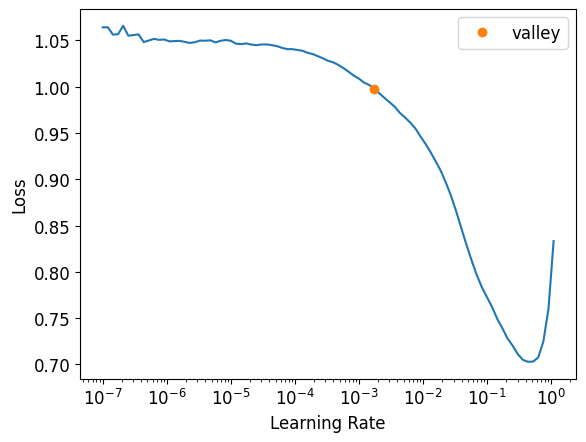

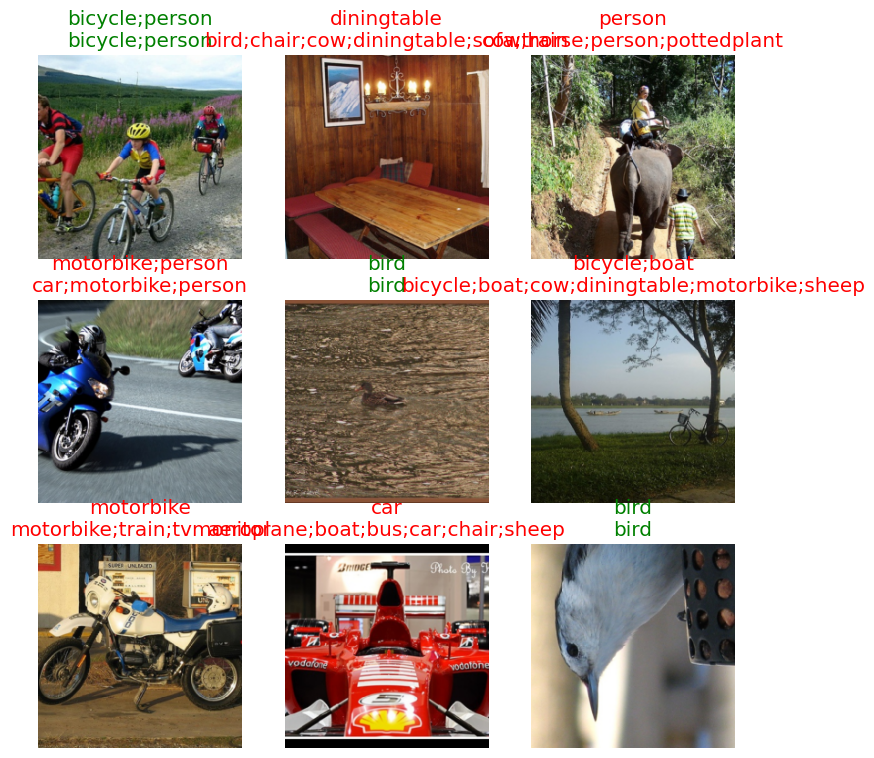

In [ ]:
# Example-2
pascal = DataBlock(blocks=(ImageBlock, MultiCategoryBlock),
                   splitter=ColSplitter('is_valid'),
                   get_x=ColReader('fname', pref=str(path/'train') + os.path.sep),
                   get_y=ColReader('labels', label_delim=' '),
                   item_tfms = Resize(460),
                   batch_tfms=aug_transforms(size=224))
dls = pascal.dataloaders(df)
dls.show_batch(max_n=9)
#
f1_macro = F1ScoreMulti(thresh=0.5, average='macro')
f1_macro.name = 'F1(macro)'
f1_samples = F1ScoreMulti(thresh=0.5, average='samples')
f1_samples.name = 'F1(samples)'
learn = vision_learner(dls, resnet50, metrics=[partial(accuracy_multi, thresh=0.5), f1_macro, f1_samples]) # accuracy_multi is a FastAI metric for multi-label classification.
lr=learn.lr_find()
learn.fine_tune(2, lr[0])
learn.show_results()
#
learn.predict(path/'train/000005.jpg') # sample prediction
#



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,target,predicted,probabilities,loss
0,person,aeroplane;bottle;chair;diningtable;dog;motorbike;person;pottedplant;train;tvmonitor,"tensor([0.6261, 0.3041, 0.3976, 0.3267, 0.9837, 0.3323, 0.1561, 0.2134, 0.7972, 0.3760, 0.9858, 0.5342, 0.3427, 0.5914, 0.9665, 0.7482, 0.4280, 0.1550, 0.6203, 0.5965])",0.9800013899803162
1,diningtable,bird;chair;cow;diningtable;sofa;train,"tensor([0.4059, 0.2824, 0.5079, 0.2587, 0.3247, 0.1718, 0.0486, 0.1499, 0.9998, 0.6706, 0.9620, 0.2464, 0.1611, 0.2542, 0.0782, 0.3476, 0.4090, 0.9624, 0.6293, 0.2522])",0.9286835789680481
2,chair,bicycle;bottle;bus;chair;cow;pottedplant;sheep;sofa;train;tvmonitor,"tensor([0.2186, 0.5519, 0.2600, 0.1882, 0.6810, 0.6457, 0.0655, 0.3324, 0.9974, 0.5271, 0.4731, 0.4025, 0.2251, 0.3823, 0.0012, 0.6049, 0.6677, 0.9944, 0.7603, 0.9416])",0.9169694781303406
3,boat;person,boat;car;chair;cow;diningtable;motorbike;pottedplant;sheep;sofa;tvmonitor,"tensor([0.2621, 0.2550, 0.2613, 0.9132, 0.4008, 0.4995, 0.5741, 0.2583, 0.9121, 0.5811, 0.5855, 0.2545, 0.1458, 0.5750, 0.1452, 0.9818, 0.6311, 0.7395, 0.0512, 0.6382])",0.9092172980308533
4,sofa,bird;bus;chair;diningtable;sheep;sofa;train;tvmonitor,"tensor([0.3095, 0.4032, 0.5864, 0.4066, 0.3443, 0.6146, 0.0968, 0.4527, 0.9972, 0.4275, 0.5802, 0.1849, 0.2525, 0.3600, 0.0583, 0.4257, 0.7523, 0.9941, 0.6016, 0.8804])",0.8830689787864685
5,bicycle;person,aeroplane;car;dog;motorbike;sheep;tvmonitor,"tensor([0.8397, 0.1112, 0.0782, 0.4304, 0.4044, 0.4404, 0.9788, 0.0746, 0.1741, 0.3033, 0.4865, 0.6185, 0.2632, 0.7636, 0.3816, 0.3611, 0.6499, 0.2509, 0.3062, 0.5400])",0.8761009573936462
6,pottedplant;sofa;tvmonitor,aeroplane;bottle;bus;cat;chair;cow;diningtable;pottedplant;sofa;train;tvmonitor,"tensor([0.5793, 0.4682, 0.2129, 0.4137, 0.5091, 0.5979, 0.0471, 0.5879, 0.9989, 0.5467, 0.7836, 0.1406, 0.2720, 0.3183, 0.0393, 0.5062, 0.3227, 0.9704, 0.7319, 0.9930])",0.8648276329040527
7,person,aeroplane;bottle;bus;car;chair;dog;pottedplant;sofa;train,"tensor([0.6466, 0.2182, 0.1724, 0.2870, 0.9221, 0.7607, 0.7900, 0.0223, 0.8416, 0.4982, 0.4830, 0.5724, 0.2555, 0.2458, 0.3637, 0.8119, 0.4175, 0.5402, 0.6485, 0.0479])",0.8544130325317383
8,person,bicycle;bird;sheep,"tensor([0.3929, 0.5882, 0.9949, 0.2153, 0.4337, 0.3767, 0.4596, 0.1843, 0.2495, 0.2405, 0.4374, 0.3335, 0.1317, 0.4641, 0.0263, 0.3274, 0.5827, 0.1889, 0.2189, 0.4556])",0.8524967432022095


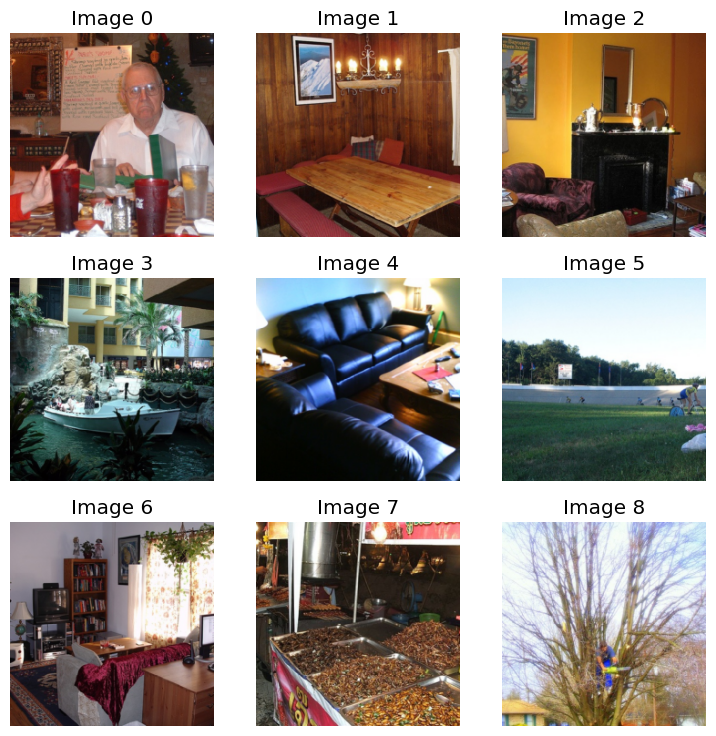

In [ ]:
# Now we  check where the model did its worse
interp = Interpretation.from_learner(learn)
interp.plot_top_losses(9)

## **Transfer learning: how to fine-tune a pretrained model**

Here we learn how to change a pre-trained model by cutting its head, adding a new head, and fine-tuning the new model. Let's start with a simple example.

In [ ]:
from fastai.vision.all import *

# A small, executable CNN to illustrate how create_body works.
m = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1),
    nn.MaxPool2d(2),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(8, 10)
)

# Verify that the model produces 10 outputs.
with torch.no_grad():
    print(m(torch.randn(2, 3, 32, 32)).shape)  # (2, 10)

# Identify pooling layers.
assert has_pool_type(m)
test_eq(
    [has_pool_type(layer) for layer in m.children()],
    [False, True, True, False, False]
)

# By default, create_body removes the last pooling layer
# and all subsequent layers.
body = create_body(m)
test_eq(len(body), 2)

# Alternatively, specify the cut position explicitly.
body_cut = create_body(m, cut=3)
test_eq(len(body_cut), 3)

#
# now let's learn how to add a new head
#
# In fastai, the model head takes nf features, runs through lin_ftrs, and out n_out classes.
#
# create_head (nf, n_out, lin_ftrs=None, ps=0.5, pool=True,
#              concat_pool=True, first_bn=True, bn_final=False,
#              lin_first=False, y_range=None)
#
# In this example you learn how to add a new head set by fastai
# The default call transforms the input in 512 features and then in n_out features
tst=create_head(10,10)  # equivalent to tst=create_head(10,10,[512])
tst

torch.Size([2, 10])


Sequential(
  (0): AdaptiveConcatPool2d(
    (ap): AdaptiveAvgPool2d(output_size=1)
    (mp): AdaptiveMaxPool2d(output_size=1)
  )
  (1): Flatten(full=False)
  (2): BatchNorm1d(20, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (3): Dropout(p=0.25, inplace=False)
  (4): Linear(in_features=20, out_features=512, bias=False)
  (5): ReLU(inplace=True)
  (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (7): Dropout(p=0.5, inplace=False)
  (8): Linear(in_features=512, out_features=10, bias=False)
)

This example below shows a  `resnet18` model, whose original head is removed and the fastai standard one is added according to the output units. `n_in` defines the number of input channels.

In [ ]:
tst = create_vision_model(models.resnet18, 10, True, n_in=3)
tst


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s]


Sequential(
  (0): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  

<div><progress max="168168549" value="168173568"></progress> 100.00% [168173568/168168549 00:02&lt;00:00]</div>

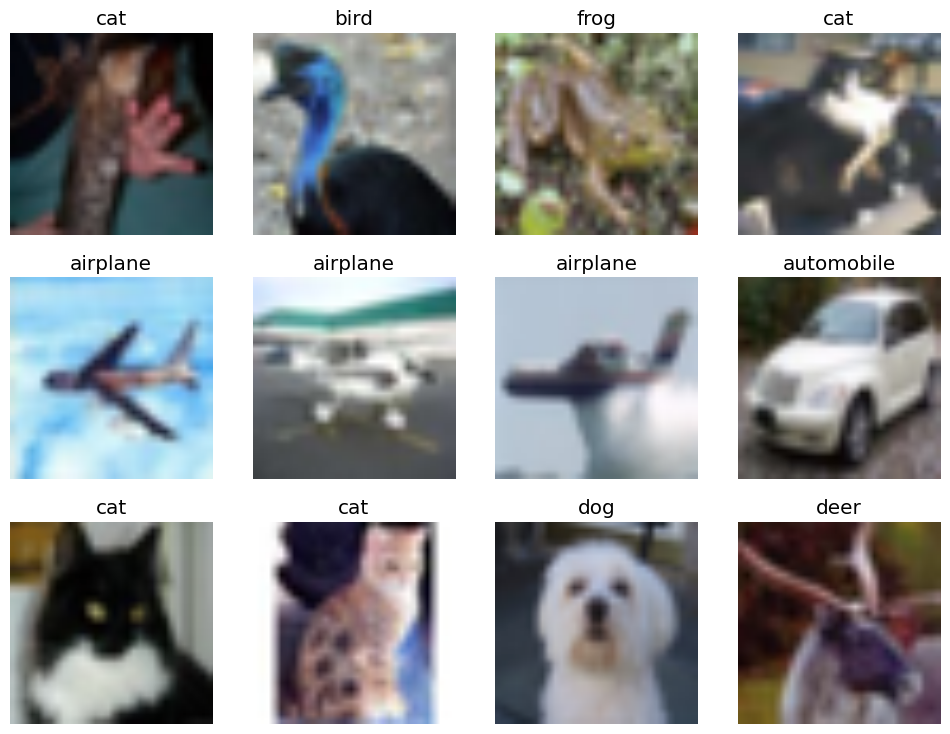

In [ ]:
path = untar_data(URLs.CIFAR)

# Create training and validation sets using only the official training images.
# The official test partition remains untouched.
CIFAR10 = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.1, seed=42),
    get_y=parent_label,
    item_tfms=Resize(224),
    batch_tfms=[
        IntToFloatTensor(),
        Normalize.from_stats(*imagenet_stats)
    ]
)

dls = CIFAR10.dataloaders(path/'train', bs=128)

dls.show_batch(max_n=12)

**Parameter groups, freezing, and discriminative learning rates**

When using transfer learning, it is common to train different parts of a neural network differently. For example, we may initially freeze the pretrained feature extractor (backbone) and train only the newly initialized classification head.

To accomplish this, FastAI needs to know how the model parameters should be divided into groups. This is the purpose of the `splitter` argument in `Learner`.

In our example, `create_vision_model()` returns a model with two main components: `tst[0]` (the convolutional backbone) and `tst[1]` (the classification head). The function `default_split` separates their parameters into two groups.

This separation allows FastAI to:

- Freeze the backbone while training the head.
- Unfreeze the complete model for fine-tuning.
- Apply different learning rates to different parameter groups.

For example, `learn.fine_tune(3)` first trains the head with the backbone frozen (one epoch by default), and then fine-tunes the network for three additional epochs. There is no need to call `learn.freeze()` explicitly before `fine_tune()`.

Importantly, `default_split` does not itself freeze any parameters or assign learning rates: it only defines the groups on which these operations can be performed.

**Do not confuse this parameter splitter with the `splitter` used in `DataBlock`, which divides examples into training and validation sets.**

When using `vision_learner()` or `unet_learner()`, FastAI normally configures an appropriate parameter splitter automatically. However, when constructing a `Learner` manually from a model created using `create_vision_model()`, we must provide it explicitly to enable this form of transfer learning.

See [FastAI documentation: default_split](https://docs.fast.ai/vision.learner.html#default_split).

In [ ]:
# Inspect the parameter groups returned by default_split.
param_groups = default_split(tst)

for i, group in enumerate(param_groups):
    n_params = sum(p.numel() for p in group)
    print(f'Parameter group {i}: {n_params:,} parameters')

Parameter group 0: 11,176,512 parameters
Parameter group 1: 532,480 parameters


In [ ]:
# Split the model into backbone and classification head.
learn = Learner(
    dls,
    tst,
    splitter=default_split,
    metrics=accuracy
)

# First train the head with a frozen backbone,
# then fine-tune the complete network.
learn.fine_tune(3)

epoch,train_loss,valid_loss,accuracy,time
0,0.709724,0.486263,0.836200,00:22


epoch,train_loss,valid_loss,accuracy,time
0,0.431380,0.316164,0.892000,00:26
1,0.278749,0.248546,0.914000,00:26
2,0.198820,0.237555,0.915800,00:26


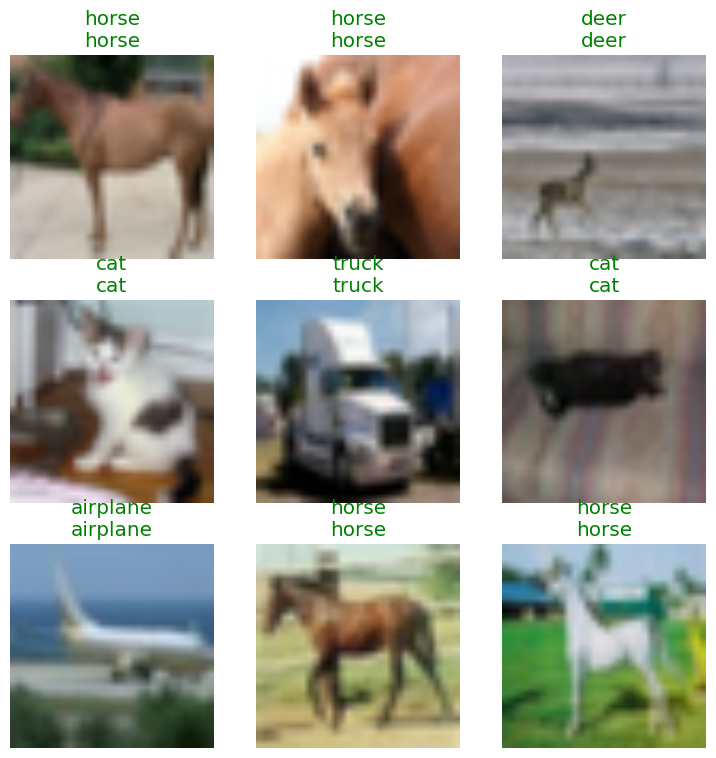

In [ ]:
learn.show_results()

**Discriminative learning rates**

Once the network has been unfrozen, we can assign different learning rates to different parameter groups. This is known as *discriminative learning rates*.

In the following example, `lr_max=slice(1e-6, 1e-4)` assigns a smaller learning rate to the pretrained backbone and a larger learning rate to the classification head. This is useful because the backbone already contains learned representations that we generally want to modify more conservatively, whereas the head is more specific to the new task.

The `splitter` determines which parameters belong to each group, while `lr_max` determines the learning rates applied to those groups. Since our model has two parameter groups, the two values correspond to the backbone and the head, respectively.

In [ ]:
# example of use of discriminative learning, using slice for assigning smaller learning rates in the first layers and higher values in head layers
learn.fit_one_cycle(3, lr_max=slice(1e-6, 1e-4))

epoch,train_loss,valid_loss,accuracy,time
0,0.180017,0.234332,0.917800,00:26
1,0.167137,0.231700,0.919800,00:26
2,0.171766,0.230250,0.918600,00:26



**How to add my own head or add new layers**

You can replace the standard classification head of a pretrained model with your own architecture. The dimensions of the custom head must be compatible with the output of the convolutional backbone.

For example, the ResNet101 backbone produces 2048 feature channels. We can apply global average pooling to obtain one value per channel, followed by a fully connected layer with one output per class.

```python
from torchvision.models import resnet101

custom_head = nn.Sequential(
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(2048, dls.c)
)

learn = vision_learner(
    dls,
    resnet101,
    pretrained=True,
    custom_head=custom_head,
    metrics=accuracy
)

learn.summary()
```

The global average pooling operation transforms a tensor of shape `(B, 2048, H, W)` into `(B, 2048, 1, 1)`. The flattening operation then produces a tensor of shape `(B, 2048)`, which is compatible with the final linear layer.

See https://docs.fast.ai/vision.learner.html#create_vision_model





**How to freeze the parameters of a pretrained model**

In fastai, `Learner.freeze()` and `Learner.freeze_to(n)` allow us to freeze selected groups of model parameters during training. Freezing a parameter means that its weights will not be updated by the optimizer.

However, Batch Normalization layers require special attention. Besides their trainable parameters, these layers maintain running statistics, such as `running_mean` and `running_var`.

By default, fastai may keep BatchNorm parameters trainable even when the rest of the backbone is frozen. Setting `train_bn=False` prevents this behavior, but it does not necessarily freeze the running statistics.

To keep the pretrained backbone, including its BatchNorm statistics, frozen during the initial training phase, we can use:

```python
learn = vision_learner(
    dls,
    resnet18,
    pretrained=True,
    train_bn=False,
    cbs=BnFreeze
)

learn.freeze()
```

`BnFreeze` keeps the running statistics of non-trainable BatchNorm layers fixed.

This distinction is particularly important when comparing a strictly frozen feature extractor with a fine-tuned model.

See https://docs.fast.ai/callback.training.html#BnFreeze